# Assignment 3 — Regularization and Stability

*Statistical Methods for Machine Learning, A.Y. 2025/26, Università degli Studi di Milano.*

**Question.** Bousquet & Elisseeff (2002) show that an algorithm whose output barely changes when
one training point is removed (*stable*) must have a small generalisation gap. For ridge regression
the stability constant shrinks like $1/(\lambda n)$. We check this empirically:

1. does a larger regularisation strength $\lambda$ make ridge regression more stable?
2. do more stable models have a smaller gap between test and training error?
3. what does stability **not** tell us (the bias side of the trade-off)?

All learning code is written from scratch in the `regstab` package (numpy only); this notebook just
runs the experiments and draws the figures. Run it with *Restart & Run All*.

## 1. Setup

`sys.path` gets the project root so that `import regstab` works when the notebook is run from
inside `notebooks/`. Every setting (seed, $\lambda$ grid, sizes) lives in `regstab/config.py`.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # project root -> makes `regstab` importable

import numpy as np
from regstab import config, plotting
from regstab.data import diabetes_split, load_diabetes_raw, make_synthetic, make_true_weights
from regstab.experiments import lambda_sweep, size_sweep

%matplotlib inline
print("seed:", config.SEED, "| repetitions R:", config.R,
      "| lambda grid:", f"{config.LAMBDAS[0]:.0e} ... {config.LAMBDAS[-1]:.0e} ({len(config.LAMBDAS)} values)")

seed: 2026 | repetitions R: 20 | lambda grid: 1e-05 ... 1e+02 (30 values)


## 2. Datasets — and why their conditioning matters

* **Synthetic**: $x \sim \mathcal N(0,\Sigma)$ with $\Sigma_{ij}=0.9^{|i-j|}$, $d=30$, $y = x^\top w^* + \varepsilon$,
  $\varepsilon\sim\mathcal N(0,1)$. Training size $n=40$, fresh test set of 2000 points. The best possible
  test MSE (Bayes error) is $\sigma^2 = 1$.
* **Diabetes** (442 patients, 10 features): random test set of 142 patients and a training subsample of
  $n=50$ from the rest; a contrast run uses all $n=300$ remaining patients.

The quantity that drives everything below is the **condition number** of $Z^\top Z$ (standardised
training features): the ratio between its largest and smallest eigenvalue. OLS divides by the
eigenvalues, so a huge condition number means a tiny change in the data can move the OLS solution a
lot. Ridge adds $n\lambda$ to every eigenvalue, which caps this amplification.

In [2]:
def cond_ZtZ(X):
    # Standardise with the training set's own statistics, as the models do.
    Z = (X - X.mean(0)) / X.std(0)
    ev = np.linalg.eigvalsh(Z.T @ Z)
    return ev.max() / ev.min(), ev.min()

rng = np.random.default_rng(config.SEED)
w_star = make_true_weights(config.SYN_D, rng)
X_syn, _ = make_synthetic(config.SYN_N_TRAIN, w_star, config.SYN_RHO, config.SYN_SIGMA, rng)
X_all, y_all = load_diabetes_raw()
X_d50, *_ = diabetes_split(X_all, y_all, config.DIAB_N_TRAIN, config.DIAB_N_TEST, rng)
X_d300, *_ = diabetes_split(X_all, y_all, config.DIAB_N_TRAIN_FULL, config.DIAB_N_TEST, rng)

for name, X in [("synthetic, n=40, d=30", X_syn), ("Diabetes, n=50, d=10", X_d50), ("Diabetes, n=300, d=10", X_d300)]:
    k, ev_min = cond_ZtZ(X)
    print(f"{name:24s} condition number of Z^T Z = {k:10.1f}   smallest eigenvalue = {ev_min:8.4f}")

synthetic, n=40, d=30    condition number of Z^T Z =     5469.9   smallest eigenvalue =   0.0969
Diabetes, n=50, d=10     condition number of Z^T Z =     1184.7   smallest eigenvalue =   0.1796
Diabetes, n=300, d=10    condition number of Z^T Z =      505.3   smallest eigenvalue =   2.4187


## 3. Run the experiments

For every repetition (new random split or new synthetic draw) and every $\lambda$, `loo_stability`
fits the model on the full training set $S$ and then **refits it $n$ times**, each time on $S$ without
one point. It records train/test MSE and three stability metrics measured on the fixed test set:

* `mean_pred_change` $= \frac1n\sum_i \frac1m\sum_j |f_S(x'_j) - f_{S\setminus i}(x'_j)|$ (main metric);
* `max_pred_change` $= \max_i \max_j |f_S(x'_j) - f_{S\setminus i}(x'_j)|$ (proxy for the paper's uniform stability $\beta$);
* `mean_loss_change`: same as the first, on the squared loss instead of the prediction.

| run | dataset | $n_\text{train}$ | purpose |
|---|---|---|---|
| A | synthetic | 40 | main |
| B | Diabetes | 50 | main |
| C | Diabetes | 300 | contrast: plenty of data |
| D | synthetic | 35 … 500 | extension: effect of dataset size |

This takes about a minute and a half (≈ 400 000 small model fits).

In [3]:
t0 = time.time()
res_syn = lambda_sweep("synthetic", config.SYN_N_TRAIN, config.LAMBDAS, config.R, config.SEED)
res_d50 = lambda_sweep("diabetes", config.DIAB_N_TRAIN, config.LAMBDAS, config.R, config.SEED)
res_d300 = lambda_sweep("diabetes", config.DIAB_N_TRAIN_FULL, config.LAMBDAS, config.R, config.SEED)
res_size = size_sweep(config.SIZE_N_VALUES, config.SIZE_LAMBDAS, config.R, config.SEED)
print(f"all experiments done in {time.time() - t0:.0f} s")

main = {"Synthetic": res_syn, "Diabetes": res_d50}
FIG = config.FIG_DIR

all experiments done in 85 s


## 4. Figures

Shared conventions: solid line = mean over the 20 repetitions, shaded band = ±1 standard deviation,
**dashed** line = OLS ($\lambda=0$, drawn as a horizontal reference because 0 cannot sit on a log axis),
**dotted** gray = theoretical reference.

### Figure 1 — Stability vs regularisation

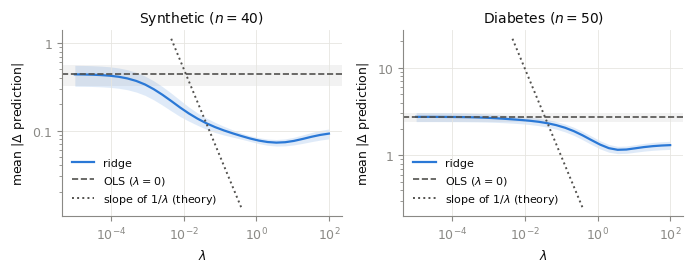

In [4]:
plotting.plot_stability_vs_lambda(main, FIG / "fig1_stability_vs_lambda.pdf");

**What to notice.**
* For tiny $\lambda$ ridge coincides with OLS (dashed line).
* Stability improves with $\lambda$ until $\lambda\approx 3.6$: about **6×** on the synthetic data (0.44 → 0.073) and **2.4×** on Diabetes (2.75 → 1.15).
* Beyond that it rises slightly again. The change caused by removing point $i$ is approximately (exactly, for a fixed penalty and scaling) *influence of $i$* × *leave-one-out residual of $i$*: the influence keeps shrinking (on average not below about $1/n$, because the intercept is not penalised), while the residual grows once the model underfits. Both factors are measured in §6.
* The decay is much flatter than the $1/\lambda$ slope guide (slope ≈ −0.18 / −0.11 over $\lambda\in[10^{-3},3.6]$): for small $\lambda$ the bound is loose, and the plateau shows the theorem's assumptions (everything penalised, bounded loss) are not met here.

### Figure 2 — Train and test error vs regularisation

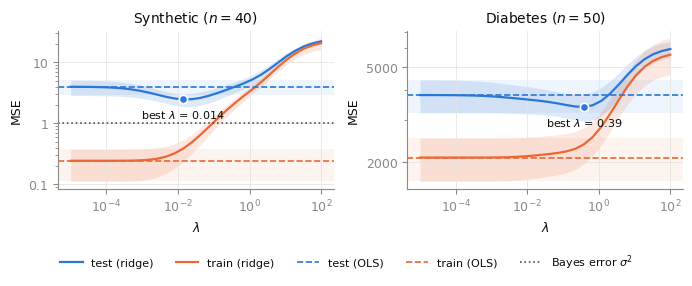

In [5]:
plotting.plot_error_vs_lambda(main, FIG / "fig2_error_vs_lambda.pdf",
                              bayes_mse={"Synthetic": config.SYN_SIGMA**2, "Diabetes": None});

**What to notice.**
* The training error grows monotonically with $\lambda$; the test error is **U-shaped** (variance ↓, then bias ↑).
* Synthetic: best $\lambda\approx0.014$, test MSE 2.46 vs 3.97 for OLS (Bayes error 1). Diabetes: best $\lambda\approx0.39$, 3411 vs 3823.
* At $\lambda=100$ both errors explode (underfitting): the most *stable* models are not the most *accurate*.

### Figure 3 — Stability vs generalisation gap

Each point is one $\lambda$ (colour), averaged over repetitions; the cross is OLS. If stability
controls generalisation, points to the left (more stable) should have a smaller gap.

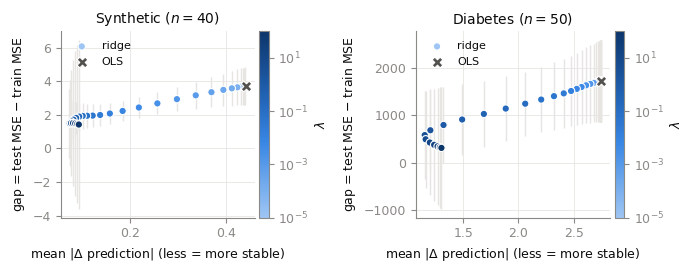

In [6]:
plotting.plot_stability_vs_gap(main, FIG / "fig3_stability_vs_gap.pdf");

**What to notice.**
* Along the $\lambda$ curve, more stable (left) goes with a smaller gap (down): rank correlation 0.94 (synthetic) and 0.97 (Diabetes); 0.996 / 1.000 for the worst-case metric (Figure 6, top).
* **Caveat:** both quantities are (nearly) monotone in $\lambda$, so this correlation is partly automatic. The stronger check is in §6: over the 45 $(n,\lambda)$ settings of the size sweep, where two parameters vary, the correlation is still ≈ 0.98–0.99.
* The hook of dark points on the left is the large-$\lambda$ region where the average stability rises again while the gap keeps shrinking.

### Figure 4 — Extension: effect of the training-set size

Synthetic data, $d=30$, $n$ from 35 to 500, four values of $\lambda$ plus OLS. The bound predicts
ridge stability $\propto 1/n$ at fixed $\lambda$.

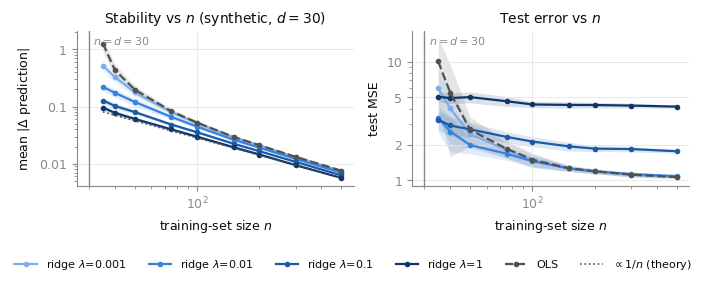

In [7]:
plotting.plot_size_sweep(res_size, config.SYN_D, FIG / "fig4_size_sweep.pdf");

**What to notice.**
* At fixed $\lambda$ stability decays roughly like $1/n$: fitted log-log slopes (over $n\ge50$) between −1.03 ($\lambda=1$) and −1.35 ($\lambda=10^{-3}$).
* OLS blows up as $n$ approaches $d=30$ (1.26 at $n=35$) and becomes as stable as ridge for large $n$.
* Strong regularisation stays biased even with 500 points (test MSE ≈ 4.2 for $\lambda=1$ vs ≈ 1.06 for OLS).

### Figure 5 — Contrast: Diabetes with a small vs a large training set

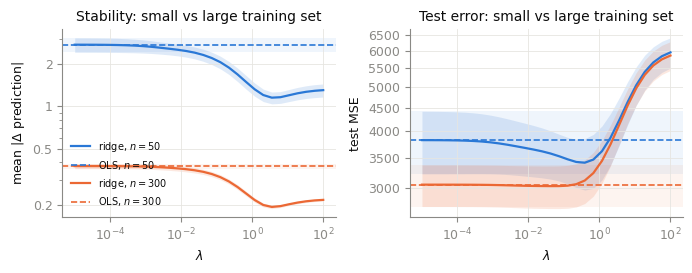

In [8]:
plotting.plot_contrast(res_d50, res_d300, FIG / "fig5_contrast_diabetes.pdf");

**What to notice.**
* With $n=300$ OLS is already ~7× more stable than with $n=50$ (0.38 vs 2.75).
* Ridge still halves the prediction change, but the test error barely moves (3031 vs 3054; ridge wins in 11/20 repetitions).
* Regularisation matters when data is scarce or ill-conditioned.

### Figure 6 — Do the other two stability metrics agree?

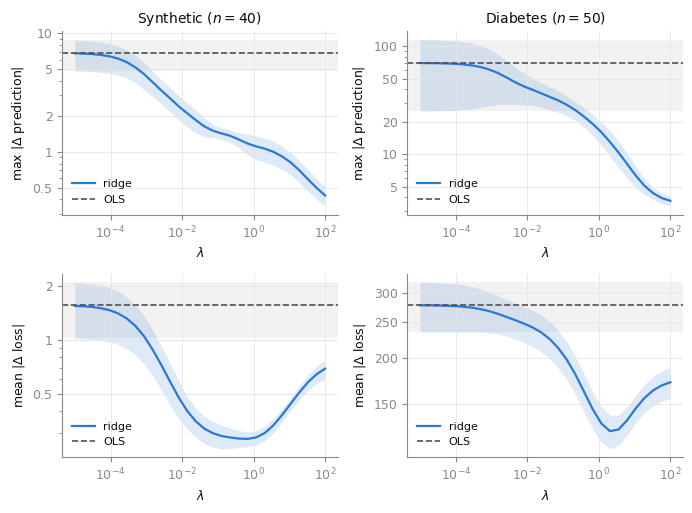

In [9]:
plotting.plot_metric_agreement(main, FIG / "fig6_metric_agreement.pdf");

**What to notice.**
* The **worst-case** change (top) decreases monotonically: 16× (synthetic) and 19× (Diabetes) from OLS to $\lambda=100$. This is the closest proxy to the paper's uniform stability $\beta$.
* The **loss** change (bottom) is U-shaped like the average prediction change, with minimum near $\lambda\approx0.7$–$2$.

## 5. Summary table — OLS vs best-$\lambda$ ridge

"Best" is the $\lambda$ with the lowest mean test MSE in the sweep. This is a **descriptive** summary
of the curves, not a model-selection procedure (picking $\lambda$ on the test set is optimistic).
Values are mean ± std over the 20 repetitions; "stability" is `mean_pred_change`.

In [10]:
rows = plotting.summary_rows({"Synthetic": res_syn, "Diabetes ($n=50$)": res_d50, "Diabetes ($n=300$)": res_d300})
for r in rows:
    fmt = lambda v: "   --" if v is None else f"{v[0]:9.3f} ± {v[1]:7.3f}"
    print(f"{r['dataset']:20s} {r['model'][:5]:5s} lam={r['lam']:<8.2g} train={fmt(r['train_mse'])} "
          f"test={fmt(r['test_mse'])} gap={fmt(r['gap'])} stab={fmt(r['mean_pred_change'])} R2={fmt(r['test_r2'])}")

(FIG / "summary_table.tex").write_text(plotting.rows_to_latex(rows) + "\n")
print("\nLaTeX table written to", FIG / "summary_table.tex")

Synthetic            OLS   lam=0        train=    0.244 ±   0.132 test=    3.973 ±   1.122 gap=    3.729 ±   1.118 stab=    0.441 ±   0.119 R2=   --
Synthetic            Ridge lam=0.014    train=    0.383 ±   0.148 test=    2.464 ±   0.578 gap=    2.081 ±   0.614 stab=    0.157 ±   0.029 R2=   --
Diabetes ($n=50$)    OLS   lam=0        train= 2095.571 ± 429.453 test= 3822.877 ± 599.310 gap= 1727.307 ± 863.722 stab=    2.746 ±   0.323 R2=    0.358 ±   0.106
Diabetes ($n=50$)    Ridge lam=0.39     train= 2381.446 ± 410.391 test= 3410.932 ± 439.873 gap= 1029.485 ± 702.328 stab=    1.687 ±   0.185 R2=    0.429 ±   0.057
Diabetes ($n=300$)   OLS   lam=0        train= 2820.909 ± 147.628 test= 3053.517 ± 318.954 gap=  232.608 ± 465.445 stab=    0.376 ±   0.016 R2=    0.489 ±   0.038
Diabetes ($n=300$)   Ridge lam=0.042    train= 2846.504 ± 149.677 test= 3030.785 ± 324.214 gap=  184.281 ± 473.327 stab=    0.342 ±   0.015 R2=    0.493 ±   0.036

LaTeX table written to /Users/preciousprince/Desk

## 6. Every statistic quoted in the report and study guide

So that each number in `report/NOTES.md` and `STUDY_GUIDE.md` can be traced to code. Fit windows are stated explicitly
because a slope depends on the range it is fitted over.

* **Across-$\lambda$ Spearman** (stability vs gap along the $\lambda$ curve): both quantities move monotonically with $\lambda$
  over most of the grid, so values near ±1 are partly automatic. *Consistent with* the theory, but a weak test.
* **Pooled Spearman over the size sweep**: stability and gap vary with both $n$ and $\lambda$ (45 configurations), so a high
  correlation is *not* automatic. This is the stronger check.
* **Across-repetition Spearman at fixed $\lambda$**: are the random draws that happen to be more stable also those with a
  smaller gap? The theorem bounds the *expected* gap of an algorithm and says nothing about individual draws, so this is
  reported for honesty, not as a test of the theorem.

In [11]:
from regstab.analysis import (spearman, loglog_slope, influence_and_residual,
                              across_reps_spearman, pooled_spearman)
from regstab.models import RidgeRegression

lam = config.LAMBDAS
for name, r in [("Synthetic n=40", res_syn), ("Diabetes n=50", res_d50), ("Diabetes n=300", res_d300)]:
    s = r["ridge"]["mean_pred_change"].mean(0)
    a = int(s.argmin())
    b = int(r["ridge"]["test_mse"].mean(0).argmin())
    gap = r["ridge"]["gap"].mean(0)
    win = (lam >= 1e-3) & (lam <= lam[a])
    print(f"== {name}")
    print(f"  mean|dpred|: OLS {r['ols']['mean_pred_change'].mean():.4g}, min {s[a]:.4g} at lam={lam[a]:.3g} "
          f"({r['ols']['mean_pred_change'].mean()/s[a]:.2f}x better), lam=100: {s[-1]:.4g}")
    mx = r["ridge"]["max_pred_change"].mean(0)
    print(f"  max|dpred|: OLS {r['ols']['max_pred_change'].mean():.4g} -> lam=100 {mx[-1]:.4g} "
          f"({r['ols']['max_pred_change'].mean()/mx[-1]:.1f}x), monotone decreasing: {bool(np.all(np.diff(mx) < 0))}")
    lo = r["ridge"]["mean_loss_change"].mean(0)
    print(f"  mean|dloss|: OLS {r['ols']['mean_loss_change'].mean():.4g}, min {lo.min():.4g} at lam={lam[lo.argmin()]:.3g}")
    print(f"  log-log slope of mean|dpred| vs lam, window lam in [1e-3, {lam[a]:.3g}]: {loglog_slope(lam[win], s[win]):.3f}")
    print(f"  best lam (test MSE) {lam[b]:.3g}: ridge beats OLS in "
          f"{int((r['ridge']['test_mse'][:, b] < r['ols']['test_mse']).sum())}/{config.R} repetitions; "
          f"test MSE at lam=100: {r['ridge']['test_mse'].mean(0)[-1]:.4g}")
    print(f"  gap: OLS {r['ols']['gap'].mean():.4g} -> lam=100 {gap[-1]:.4g}")
    for m in ["mean_pred_change", "max_pred_change", "mean_loss_change"]:
        st = r["ridge"][m].mean(0)
        ac = across_reps_spearman(r["ridge"][m], r["ridge"]["gap"])
        print(f"  Spearman({m}, gap): across lam {spearman(st, gap):.3f} | "
              f"across reps at fixed lam: median {np.median(ac):.2f} (range {ac.min():.2f}..{ac.max():.2f})")

print("== Size sweep (synthetic, d=30)")
n = res_size["n_values"]
for j, l in enumerate(res_size["lambdas"]):
    s = res_size["ridge"]["mean_pred_change"][:, :, j].mean(0)
    t = res_size["ridge"]["test_mse"][:, :, j].mean(0)
    print(f"  ridge lam={l:g}: slope vs n (window n>=50) {loglog_slope(n[n >= 50], s[n >= 50]):.3f}; "
          f"test MSE n=35 {t[0]:.3g} -> n=500 {t[-1]:.3g}")
s = res_size["ols"]["mean_pred_change"].mean(0); t = res_size["ols"]["test_mse"].mean(0)
print(f"  OLS: mean|dpred| n=35 {s[0]:.3g}, n=40 {s[1]:.3g}, n=500 {s[-1]:.3g}; slope (n>=50) "
      f"{loglog_slope(n[n >= 50], s[n >= 50]):.3f}; test MSE n=35 {t[0]:.3g} -> n=500 {t[-1]:.3g}")
for m in ["mean_pred_change", "max_pred_change", "mean_loss_change"]:
    rho, k = pooled_spearman(res_size, m)
    print(f"  pooled Spearman({m}, gap) over {k} (n, lam) configurations: {rho:.3f}")

# Influence x residual decomposition on the FIRST repetition of run A (same seeds as lambda_sweep).
w_ss, rep0 = np.random.SeedSequence(config.SEED).spawn(2)
w0 = make_true_weights(config.SYN_D, np.random.default_rng(w_ss))
rng0 = np.random.default_rng(rep0)
Xa, ya = make_synthetic(config.SYN_N_TRAIN, w0, config.SYN_RHO, config.SYN_SIGMA, rng0)
Xa_te, _ = make_synthetic(config.SYN_N_TEST, w0, config.SYN_RHO, config.SYN_SIGMA, rng0)
print("== Influence x residual (run A, repetition 1); 1/n =", 1 / config.SYN_N_TRAIN)
for l in [1e-4, 1e-2, 1e-1, 1.0, 10.0, 100.0]:
    d = influence_and_residual(lambda l=l: RidgeRegression(l), Xa, ya, Xa_te)
    print(f"  lam={l:7.0e}  mean influence {d['mean_influence']:.4f}   mean |LOO residual| {d['mean_abs_residual']:.3f}")

== Synthetic n=40
  mean|dpred|: OLS 0.4409, min 0.07272 at lam=3.56 (6.06x better), lam=100: 0.09225
  max|dpred|: OLS 6.837 -> lam=100 0.4301 (15.9x), monotone decreasing: True
  mean|dloss|: OLS 1.562, min 0.2785 at lam=0.672
  log-log slope of mean|dpred| vs lam, window lam in [1e-3, 3.56]: -0.183
  best lam (test MSE) 0.0137: ridge beats OLS in 18/20 repetitions; test MSE at lam=100: 21.92
  gap: OLS 3.729 -> lam=100 1.424
  Spearman(mean_pred_change, gap): across lam 0.940 | across reps at fixed lam: median -0.47 (range -0.93..0.23)
  Spearman(max_pred_change, gap): across lam 0.996 | across reps at fixed lam: median -0.15 (range -0.53..0.24)
  Spearman(mean_loss_change, gap): across lam 0.677 | across reps at fixed lam: median 0.19 (range -0.89..0.50)
== Diabetes n=50
  mean|dpred|: OLS 2.746, min 1.153 at lam=3.56 (2.38x better), lam=100: 1.304
  max|dpred|: OLS 70.07 -> lam=100 3.692 (19.0x), monotone decreasing: True
  mean|dloss|: OLS 278.1, min 126.4 at lam=2.04
  log-log s